# 01 — Analyse exploratoire (EDA)

Objectif : comprendre l'activité de ShopPulse avant de répondre aux questions métier. Trois angles imposés : **distributions**, **saisonnalité**, **géographie**.

Les données sont lues dans la couche `core` de PostgreSQL, alimentée par le pipeline `pipelines/olist_flow.py`.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from shoppulse.geography import BrazilRegions
from shoppulse.warehouse import DataWarehouse

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
warehouse = DataWarehouse()

## 1. Chargement

Une ligne par commande : client, état, valeur des articles, frais de port, note de l'avis et dates de livraison.

In [2]:
ORDERS_SQL = """
SELECT o.order_id,
    o.status,
    o.purchase_timestamp,
    o.delivered_customer_date,
    o.estimated_delivery_date,
    c.customer_unique_id,
    c.state,
    gc.lat,
    gc.lng,
    v.items_value,
    v.freight_value,
    r.score
FROM core.orders AS o
JOIN core.customers AS c ON c.customer_id = o.customer_id
LEFT JOIN core.geolocation AS gc ON gc.zip_code_prefix = c.zip_code_prefix
LEFT JOIN (
    SELECT order_id, SUM(price) AS items_value,
        SUM(freight_value) AS freight_value
    FROM core.order_items GROUP BY order_id
) AS v ON v.order_id = o.order_id
LEFT JOIN (
    SELECT order_id, MAX(score) AS score
    FROM core.order_reviews GROUP BY order_id
) AS r ON r.order_id = o.order_id
"""
orders = warehouse.query(ORDERS_SQL)
orders["region"] = orders["state"].map(BrazilRegions.of)
delivered = orders[
    (orders["status"] == "delivered")
    & orders["delivered_customer_date"].notna()
].copy()
delivered["delivery_days"] = (
    delivered["delivered_customer_date"] - delivered["purchase_timestamp"]
).dt.days
delivered["is_late"] = (
    delivered["delivered_customer_date"].dt.normalize()
    > delivered["estimated_delivery_date"].dt.normalize()
)
print(f"{len(orders):,} commandes, dont {len(delivered):,} livrées")

99,441 commandes, dont 96,470 livrées


In [3]:
orders.describe(include='number').round(1)

,lat,lng,items_value,freight_value,score
count,99162.0,99162.0,98666.0,98666.0,98673.0
mean,-21.2,-46.2,137.8,22.8,4.1
std,5.6,4.1,210.6,21.7,1.3
min,-33.7,-72.7,0.8,0.0,1.0
25%,-23.6,-48.1,45.9,13.8,4.0
50%,-22.9,-46.6,86.9,17.2,5.0
75%,-20.1,-43.6,149.9,24.0,5.0
max,3.8,-34.8,13440.0,1795.0,5.0


## 2. Distributions

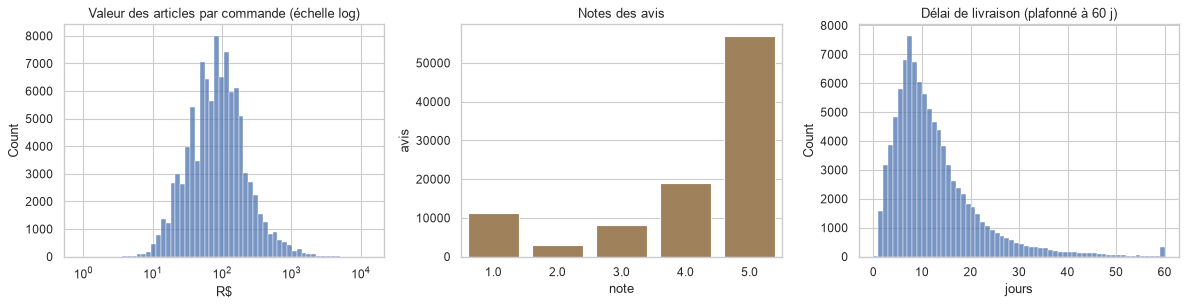

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(orders["items_value"].dropna(), bins=60, log_scale=True,
             ax=axes[0])
axes[0].set(title="Valeur des articles par commande (échelle log)",
            xlabel="R$")
sns.countplot(x="score", data=orders, color="#AA8350", ax=axes[1])
axes[1].set(title="Notes des avis", xlabel="note", ylabel="avis")
sns.histplot(delivered["delivery_days"].clip(upper=60), bins=60,
             ax=axes[2])
axes[2].set(title="Délai de livraison (plafonné à 60 j)", xlabel="jours")
plt.tight_layout()
plt.show()

In [5]:
summary = {
    "panier médian (R$)": orders["items_value"].median(),
    "panier moyen (R$)": orders["items_value"].mean(),
    "part des notes 5 (%)": 100 * (orders["score"] == 5).mean(),
    "part des notes 1-2 (%)": 100 * (orders["score"] <= 2).mean(),
    "délai médian (jours)": delivered["delivery_days"].median(),
    "taux de retard (%)": 100 * delivered["is_late"].mean(),
    "frais de port / valeur (médiane, %)": 100 * (
        orders["freight_value"] / orders["items_value"]
    ).median(),
}
{key: round(value, 1) for key, value in summary.items()}

{'panier médian (R$)': np.float64(86.9),
 'panier moyen (R$)': np.float64(137.8),
 'part des notes 5 (%)': np.float64(57.4),
 'part des notes 1-2 (%)': np.float64(14.5),
 'délai médian (jours)': np.float64(10.0),
 'taux de retard (%)': np.float64(6.8),
 'frais de port / valeur (médiane, %)': np.float64(22.4)}

**Lecture** : la valeur des commandes est très asymétrique (médiane bien inférieure à la moyenne, quelques gros paniers), d'où l'échelle log. Les notes sont polarisées : une majorité de 5, mais une part non négligeable de 1. Le délai médian est de 10 jours avec une longue traîne, et environ 7 % des commandes livrées arrivent après la date annoncée.

## 3. Saisonnalité

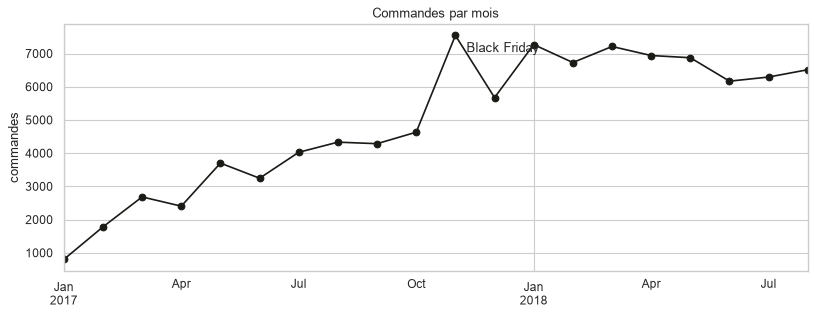

In [6]:
monthly = (
    orders.set_index("purchase_timestamp").sort_index()
    .loc["2017-01":"2018-08"]
    .resample("MS")["order_id"].count()
)
ax = monthly.plot(figsize=(12, 4), marker="o", color="#1A1A17")
ax.set(title="Commandes par mois", xlabel="", ylabel="commandes")
ax.annotate("Black Friday", xy=(monthly.idxmax(), monthly.max()),
            xytext=(10, -15), textcoords="offset points")
plt.show()

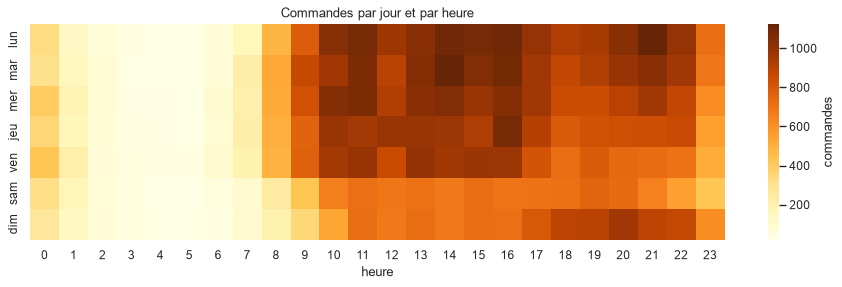

In [7]:
DAYS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
heat = orders.assign(
    day=orders["purchase_timestamp"].dt.day_of_week,
    hour=orders["purchase_timestamp"].dt.hour,
).pivot_table(index="day", columns="hour", values="order_id",
              aggfunc="count")
heat.index = DAYS
fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(heat, cmap="YlOrBr", ax=ax, cbar_kws={"label": "commandes"})
ax.set(title="Commandes par jour et par heure", xlabel="heure", ylabel="")
plt.show()

**Lecture** : forte croissance en 2017 puis plateau en 2018. Le pic de novembre 2017 correspond au Black Friday. Les achats se font surtout du lundi au mercredi, entre 10 h et 22 h ; le samedi est le jour le plus calme (-33 % par rapport au lundi). Les campagnes ont intérêt à partir en début de semaine, en journée.

## 4. Géographie

In [8]:
by_state = delivered.groupby("state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    delivery_days=("delivery_days", "median"),
).sort_values("orders", ascending=False)
by_state["late_rate"] = (100 * by_state["late_rate"]).round(1)
by_state.head(10)

,orders,late_rate,delivery_days
state,,,
SP,40494,4.5,7.0
RJ,12350,12.1,12.0
MG,11354,4.6,10.0
RS,5344,6.1,13.0
PR,4923,4.0,10.0
SC,3546,8.2,13.0
BA,3256,12.2,16.0
DF,2080,5.7,11.0
ES,1995,10.7,13.0


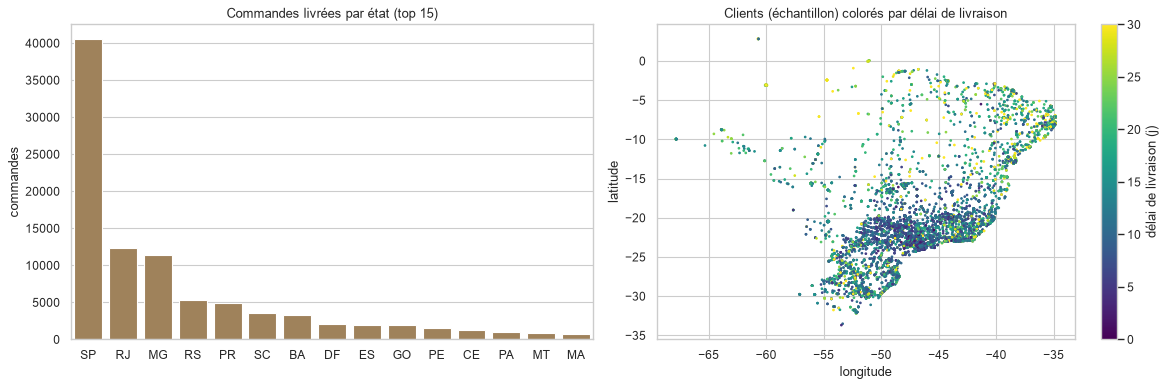

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top = by_state.head(15)
sns.barplot(x=top.index, y=top["orders"], color="#AA8350", ax=axes[0])
axes[0].set(title="Commandes livrées par état (top 15)", xlabel="",
            ylabel="commandes")
sample = delivered.dropna(subset=["lat"]).sample(20000, random_state=42)
points = axes[1].scatter(sample["lng"], sample["lat"], s=2,
                         c=sample["delivery_days"].clip(upper=30),
                         cmap="viridis")
fig.colorbar(points, ax=axes[1], label="délai de livraison (j)")
axes[1].set(title="Clients (échantillon) colorés par délai de livraison",
            xlabel="longitude", ylabel="latitude")
plt.tight_layout()
plt.show()

In [10]:
regions = delivered.groupby("region").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    delivery_days=("delivery_days", "median"),
    avg_score=("score", "mean"),
)
regions["share_pct"] = 100 * regions["orders"] / regions["orders"].sum()
regions["late_rate"] = 100 * regions["late_rate"]
regions.round(1).sort_values("orders", ascending=False)

,orders,late_rate,delivery_days,avg_score,share_pct
region,,,,,
Sudeste,66193,6.1,8.0,4.2,68.6
Sul,13813,5.9,12.0,4.2,14.3
Nordeste,9044,12.7,17.0,4.0,9.4
Centro-Oeste,5624,6.5,13.0,4.1,5.8
Norte,1796,8.6,20.0,4.0,1.9


**Lecture** : l'activité est concentrée dans le Sud-Est (SP, RJ, MG), là où se trouvent la plupart des vendeurs. Plus on s'éloigne vers le Nord et le Nord-Est, plus les délais s'allongent : 20 jours médians dans le Norte contre 8 dans le Sud-Est. Le Nordeste a le taux de retard le plus élevé (12,7 %, le double du Sud-Est) ; le Norte, livré plus lentement, est moins souvent « en retard » car les dates annoncées y sont plus prudentes. Cela motive le test du χ² (notebook 02) et l'audit d'équité par région du modèle de retard (Lot 4).

## 5. Ce qu'on retient

1. **Distributions** : paniers très asymétriques, notes polarisées, délais à longue traîne.
2. **Saisonnalité** : croissance puis plateau, pic au Black Friday, achats en semaine et en journée.
3. **Géographie** : marché concentré dans le Sud-Est ; le Nord et le Nord-Est sont livrés plus lentement, le Nordeste est le plus souvent en retard.

Questions ouvertes, traitées dans le notebook 02 : les retards font-ils vraiment baisser les notes ? Le retard dépend-il réellement de la région ?